In [86]:
# Task 3: Advanced Statistical Analysis & Hypothesis Testing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm
from statsmodels.formula.api import ols

print("All libraries imported successfully!")

All libraries imported successfully!


In [87]:
import pandas as pd

file_path = "/content/data-1 (1).xls"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (484, 33)


,Timestamp,Age (years),Gender,Year of mediacal training,Residence,"Consent to participate\nBy proceeding, I confirm that I am voluntarily participating in this research.\nI understand that this survey is anonymous and no personal identifying information will be collected and my responses will be used for research purposes. Also participation will not affect my academic, clinical or institutional standing.","Have you ever been formally diagnosed by a healthcare professional with any psychiatric illness (such as depression, anxiety disorders, OCD, bipolar disorder, schizophrenia, or others)?â€‹â€‹","Have you ever been diagnosed by a healthcare professional with any chronic medical condition such as asthma, diabetes, hypertension, hypothyroidism or others?","During the past month, how often did you do moderate-to-vigorous physical activity for at least 30 minutes (for example brisk walking, running, cycling, sports, gym workouts)?","On average, how many hours of sleep do you get per night? ______ hours",...,I spend more time than intended on my phone at night,I use my phone while lying in bed before trying to sleep,I delay my bed time because I am using social media,I continue using social media even when I feel sleepy,I sleep with my phone within my arms reach,I wake up at night to check notifications or messages,I keep thinking of social media even after I put my phone away,I feel emotionally stimulated by social media content at night,I worry I might miss out on updates if I sleep early,I feel that reducing social media use would improve my sleep
0,2025/12/20 10:09:07 AM GMT+5:30,18,2,1,1,Yes,2,1,2,7.0,...,5,5,5,5,5,2,4,3,2,5
1,2025/12/20 10:09:22 AM GMT+5:30,19,1,1,1,Yes,2,1,1,8.0,...,1,1,1,1,4,1,1,1,1,5
2,2025/12/20 10:09:29 AM GMT+5:30,19,2,1,1,Yes,1,3,3,5.5,...,4,4,4,3,5,2,3,3,2,3
3,2025/12/20 10:09:38 AM GMT+5:30,19,1,1,2,Yes,2,1,3,6.0,...,4,4,4,4,4,4,3,2,1,4
4,2025/12/20 10:09:52 AM GMT+5:30,20,2,1,1,Yes,2,2,1,7.0,...,4,5,4,3,4,2,4,5,3,4


In [88]:
print("Total responses:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
for column in df.columns:
    print(column)

Total responses: 484
Total columns: 33

Column names:
Timestamp
Age (years)
Gender
Year of mediacal training 
Residence
Consent to participate
By proceeding, I confirm that I am voluntarily participating in this research.
I understand that this survey is anonymous and no personal identifying information will be collected and my responses will be used for research purposes. Also participation will not affect my academic, clinical or institutional standing.
Have you ever been formally diagnosed by a healthcare professional with any psychiatric illness (such as depression, anxiety disorders, OCD, bipolar disorder, schizophrenia, or others)?â€‹â€‹
Have you ever been diagnosed by a healthcare professional with any chronic medical condition such as asthma, diabetes, hypertension, hypothyroidism or others?
 During the past month, how often did you do moderate-to-vigorous physical activity for at least 30 minutes (for example brisk walking, running, cycling, sports, gym workouts)?
On average, 

In [89]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Timestamp                                                                                                                                                                                                                                                                                                                                                0
Age (years)                                                                                                                                                                                                                                                                                                                                              0
Gender                                                                                                                                                                                                                                                                             

In [90]:
sleep_col = "On average, how many hours of sleep do you get per night? ______ hours"

social_col = "Average time spent on social media at night (after 9 PM) (in hours)"

print("Sleep duration:")
print(df[sleep_col].describe())

print("\nNight-time social media usage:")
print(df[social_col].describe())

Sleep duration:
count    484.000000
mean       6.728306
std        1.089686
min        4.000000
25%        6.000000
50%        7.000000
75%        7.000000
max       12.000000
Name: On average, how many hours of sleep do you get per night? ______ hours, dtype: float64

Night-time social media usage:
count    484.000000
mean       1.576116
std        1.045454
min        0.000000
25%        1.000000
50%        1.125000
75%        2.000000
max        6.500000
Name: Average time spent on social media at night (after 9 PM) (in hours), dtype: float64


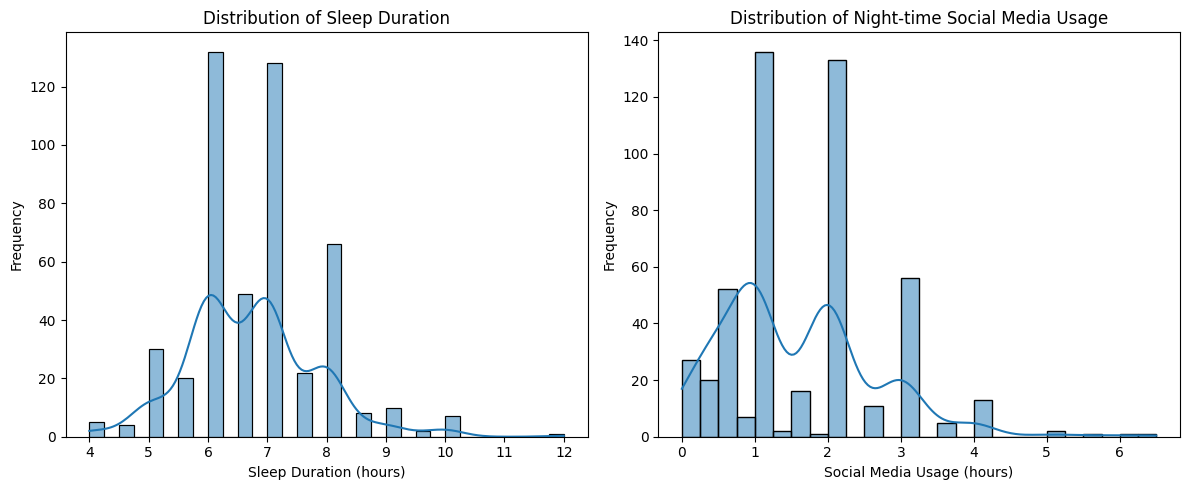

In [91]:
# Distribution plots

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df[sleep_col], kde=True)
plt.title("Distribution of Sleep Duration")
plt.xlabel("Sleep Duration (hours)")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
sns.histplot(df[social_col], kde=True)
plt.title("Distribution of Night-time Social Media Usage")
plt.xlabel("Social Media Usage (hours)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [92]:
# Shapiro-Wilk Normality Test

shapiro_sleep = stats.shapiro(df[sleep_col])
shapiro_social = stats.shapiro(df[social_col])

print("SHAPIRO-WILK TEST")
print("----------------------")

print("Sleep Duration:")
print("Statistic:", shapiro_sleep.statistic)
print("P-value:", shapiro_sleep.pvalue)

print("\nNight-time Social Media Usage:")
print("Statistic:", shapiro_social.statistic)
print("P-value:", shapiro_social.pvalue)

SHAPIRO-WILK TEST
----------------------
Sleep Duration:
Statistic: 0.9447165480713373
P-value: 1.8813599644875413e-12

Night-time Social Media Usage:
Statistic: 0.9102614026823608
P-value: 2.5603489037470627e-16


### Shapiro-Wilk Normality Test

The Shapiro-Wilk test was performed to assess the normality of sleep duration and night-time social media usage.

- Sleep duration: W = 0.9447, p < 0.001.
- Night-time social media usage: W = 0.9103, p < 0.001.

Since both p-values are below 0.05, the null hypothesis of normality is rejected for both variables. Therefore, both distributions show statistically significant deviations from normality.

In [93]:
from statsmodels.stats.diagnostic import lilliefors

# Kolmogorov-Smirnov test with Lilliefors correction

ks_sleep = lilliefors(df[sleep_col], dist='norm')
ks_social = lilliefors(df[social_col], dist='norm')

print("KOLMOGOROV-SMIRNOV TEST")
print("------------------------")

print("Sleep Duration:")
print("Statistic:", ks_sleep[0])
print("P-value:", ks_sleep[1])

print("\nNight-time Social Media Usage:")
print("Statistic:", ks_social[0])
print("P-value:", ks_social[1])

KOLMOGOROV-SMIRNOV TEST
------------------------
Sleep Duration:
Statistic: 0.16188238770157148
P-value: 0.0009999999999998899

Night-time Social Media Usage:
Statistic: 0.2092062160348736
P-value: 0.0009999999999998899


### Kolmogorov-Smirnov (Lilliefors) Normality Test

The Kolmogorov-Smirnov test with Lilliefors correction was performed to examine the normality of both variables.

- Sleep duration: D = 0.1619, p ≈ 0.001.
- Night-time social media usage: D = 0.2092, p ≈ 0.001.

Both p-values are below the significance level of 0.05. Therefore, the null hypothesis of normality is rejected for both variables.

The results are consistent with the Shapiro-Wilk test, indicating that both distributions significantly deviate from normality.

In [94]:
print("Gender categories:")
print(df["Gender"].value_counts())

print("\nResidence categories:")
print(df["Residence"].value_counts())

print("\nYear of medical training:")
print(df[year_col].value_counts())

Gender categories:
Gender
2    326
1    158
Name: count, dtype: int64

Residence categories:
Residence
1    300
2    184
Name: count, dtype: int64

Year of medical training:
Year of mediacal training 
3    169
1    133
2    130
4     52
Name: count, dtype: int64


In [95]:
# Display the exact column names containing "Year"

for col in df.columns:
    if "Year" in col or "year" in col:
        print(repr(col))

'Age (years)'
'Year of mediacal training '


In [96]:
year_col = "Year of mediacal training "

print("Year of medical training:")
print(df[year_col].value_counts())

Year of medical training:
Year of mediacal training 
3    169
1    133
2    130
4     52
Name: count, dtype: int64


In [97]:
print("DATA TYPES")
print(df.dtypes)

print("\nUNIQUE VALUES")
for col in [sleep_col, social_col, "Gender", "Residence", year_col]:
    print("\n", col)
    print(df[col].unique())

DATA TYPES
Timestamp                                                                                                                                                                                                                                                                                                                                                 object
Age (years)                                                                                                                                                                                                                                                                                                                                                int64
Gender                                                                                                                                                                                                                                                                                     

In [98]:
from scipy.stats import ttest_ind, mannwhitneyu
from statsmodels.stats.weightstats import DescrStatsW, CompareMeans

def compare_groups(data, group_col, outcome_col):
    groups = sorted(data[group_col].unique())

    group1 = data.loc[data[group_col] == groups[0], outcome_col]
    group2 = data.loc[data[group_col] == groups[1], outcome_col]

    # Welch's independent t-test
    t_result = ttest_ind(group1, group2, equal_var=False)

    # 95% confidence interval for mean difference
    comparison = CompareMeans(
        DescrStatsW(group1),
        DescrStatsW(group2)
    )
    ci = comparison.tconfint_diff(usevar='unequal')

    # Mann-Whitney U test
    u_result = mannwhitneyu(
        group1, group2, alternative='two-sided'
    )

    print("\nGrouping variable:", group_col)
    print("Group codes:", groups)
    print("Group 1 size:", len(group1))
    print("Group 2 size:", len(group2))

    print("\nWelch's Independent T-test")
    print("T-statistic:", t_result.statistic)
    print("P-value:", t_result.pvalue)
    print("95% CI for mean difference:", ci)

    print("\nMann-Whitney U Test")
    print("U-statistic:", u_result.statistic)
    print("P-value:", u_result.pvalue)


compare_groups(df, "Gender", sleep_col)
compare_groups(df, "Residence", sleep_col)


Grouping variable: Gender
Group codes: [np.int64(1), np.int64(2)]
Group 1 size: 158
Group 2 size: 326

Welch's Independent T-test
T-statistic: -1.387521654791354
P-value: 0.1662750930296664
95% CI for mean difference: (np.float64(-0.3538294792211233), np.float64(0.0611759108433966))

Mann-Whitney U Test
U-statistic: 23785.0
P-value: 0.1631747615246827

Grouping variable: Residence
Group codes: [np.int64(1), np.int64(2)]
Group 1 size: 300
Group 2 size: 184

Welch's Independent T-test
T-statistic: 0.439325153430709
P-value: 0.6606553250924739
95% CI for mean difference: (np.float64(-0.15257129301632633), np.float64(0.24039737997284805))

Mann-Whitney U Test
U-statistic: 28073.5
P-value: 0.7461871827139975


### Independent T-test and Mann-Whitney U Test

Two-group comparisons were conducted to examine differences in sleep duration.

**1. Gender groups**

- Welch's t-test: t = -1.3875, p = 0.1663.
- Mann-Whitney U test: U = 23785, p = 0.1632.
- 95% CI for mean difference: [-0.3538, 0.0612].

Both tests showed no statistically significant difference in sleep duration between the two gender-coded groups.

**2. Residence groups**

- Welch's t-test: t = 0.4393, p = 0.6607.
- Mann-Whitney U test: U = 28073.5, p = 0.7462.
- 95% CI for mean difference: [-0.1526, 0.2404].

Both tests showed no statistically significant difference in sleep duration between the two residence-coded groups.

All p-values were greater than 0.05. Therefore, the null hypotheses were not rejected for either comparison.

In [99]:
from scipy.stats import f_oneway, levene
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Separate sleep duration by academic year
year_groups = [
    df.loc[df[year_col] == year, sleep_col]
    for year in sorted(df[year_col].unique())
]

# Group descriptive statistics
print("SLEEP DURATION BY ACADEMIC YEAR")
print(df.groupby(year_col)[sleep_col].agg(
    ["count", "mean", "std", "median"]
))

# Levene's test for equal variances
lev = levene(*year_groups)
print("\nLevene's Test")
print("Statistic:", lev.statistic)
print("P-value:", lev.pvalue)

# One-Way ANOVA
anova_result = f_oneway(*year_groups)

print("\nONE-WAY ANOVA")
print("F-statistic:", anova_result.statistic)
print("P-value:", anova_result.pvalue)

# Tukey HSD post-hoc test
tukey = pairwise_tukeyhsd(
    endog=df[sleep_col],
    groups=df[year_col].astype(str),
    alpha=0.05
)

print("\nTUKEY HSD POST-HOC TEST")
print(tukey)

SLEEP DURATION BY ACADEMIC YEAR
                            count      mean       std  median
Year of mediacal training                                    
1                             133  6.796992  1.088921    7.00
2                             130  6.653846  1.101173    6.75
3                             169  6.822485  1.086099    7.00
4                              52  6.432692  1.038612    6.50

Levene's Test
Statistic: 0.2956863490005639
P-value: 0.8285246074490135

ONE-WAY ANOVA
F-statistic: 2.0889467504417323
P-value: 0.10081920832845247

TUKEY HSD POST-HOC TEST
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2  -0.1431 0.7088 -0.4885 0.2022  False
     1      3   0.0255 0.9971  -0.299   0.35  False
     1      4  -0.3643  0.171 -0.8222 0.0936  False
     2      3   0.1686 0.5435  -0.158 0.4953  False
     2      4  -0.2212  0.601 -0.6806 0.2382  False
     3

### One-Way ANOVA and Tukey HSD Analysis

One-Way ANOVA was conducted to compare average sleep duration among four academic-year groups.

**Descriptive statistics:**
- Year 1: Mean = 6.80 hours (n = 133).
- Year 2: Mean = 6.65 hours (n = 130).
- Year 3: Mean = 6.82 hours (n = 169).
- Year 4: Mean = 6.43 hours (n = 52).

**Levene's Test:**
- Statistic = 0.2957.
- p-value = 0.8285.

The equal-variance assumption was supported.

**One-Way ANOVA:**
- F-statistic = 2.0889.
- p-value = 0.1008.

Since p > 0.05, the null hypothesis was not rejected. There was no statistically significant difference in mean sleep duration among the four academic-year groups.

**Tukey HSD Post-hoc Test:**

None of the six pairwise comparisons showed a statistically significant difference (all adjusted p-values > 0.05).

Therefore, no significant pairwise differences in sleep duration were identified among the academic-year groups.

In [100]:
# Check group sizes for Two-Way ANOVA

print(pd.crosstab(
    df[year_col],
    df["Gender"],
    margins=True
))

Gender                        1    2  All
Year of mediacal training                
1                            38   95  133
2                            41   89  130
3                            58  111  169
4                            21   31   52
All                         158  326  484


In [101]:
# Prepare the data for Two-Way ANOVA

import statsmodels.api as sm
from statsmodels.formula.api import ols

analysis_df = df[[sleep_col, year_col, "Gender"]].copy()

analysis_df = analysis_df.rename(columns={
    sleep_col: "sleep_hours",
    year_col: "academic_year"
})

# Run Two-Way ANOVA with interaction
model = ols(
    "sleep_hours ~ C(academic_year, Sum) * C(Gender, Sum)",
    data=analysis_df
).fit()

anova_results = sm.stats.anova_lm(model, typ=3)

print(anova_results)

                                            sum_sq     df             F  \
Intercept                             15914.113397    1.0  13657.523086   
C(academic_year, Sum)                     4.451352    3.0      1.273386   
C(Gender, Sum)                            0.562233    1.0      0.482509   
C(academic_year, Sum):C(Gender, Sum)      9.527730    3.0      2.725572   
Residual                                554.648008  476.0           NaN   

                                        PR(>F)  
Intercept                             0.000000  
C(academic_year, Sum)                 0.282852  
C(Gender, Sum)                        0.487627  
C(academic_year, Sum):C(Gender, Sum)  0.043679  
Residual                                   NaN  


In [102]:
# Mean sleep duration for each Year and Gender group

group_means = analysis_df.groupby(
    ["academic_year", "Gender"]
)["sleep_hours"].agg(["count", "mean", "std"])

print(group_means.round(3))


                      count   mean    std
academic_year Gender                     
1             1          38  6.737  1.277
              2          95  6.821  1.010
2             1          41  6.817  1.133
              2          89  6.579  1.084
3             1          58  6.491  0.901
              2         111  6.995  1.137
4             1          21  6.452  1.094
              2          31  6.419  1.017


In [103]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

results = []

for year in sorted(analysis_df["academic_year"].unique()):

    group1 = analysis_df[
        (analysis_df["academic_year"] == year) &
        (analysis_df["Gender"] == 1)
    ]["sleep_hours"]

    group2 = analysis_df[
        (analysis_df["academic_year"] == year) &
        (analysis_df["Gender"] == 2)
    ]["sleep_hours"]

    test = ttest_ind(group1, group2, equal_var=False)

    results.append({
        "Academic Year": year,
        "Mean Gender 1": group1.mean(),
        "Mean Gender 2": group2.mean(),
        "Mean Difference (1-2)": group1.mean() - group2.mean(),
        "P-value": test.pvalue
    })

results_df = pd.DataFrame(results)

# Correct the four p-values using Holm's method
results_df["Holm Adjusted P-value"] = multipletests(
    results_df["P-value"],
    method="holm"
)[1]

print(results_df.round(4))

   Academic Year  Mean Gender 1  Mean Gender 2  Mean Difference (1-2)  \
0              1         6.7368         6.8211                -0.0842   
1              2         6.8171         6.5787                 0.2384   
2              3         6.4914         6.9955                -0.5041   
3              4         6.4524         6.4194                 0.0330   

   P-value  Holm Adjusted P-value  
0   0.7176                 1.0000  
1   0.2622                 0.7866  
2   0.0020                 0.0080  
3   0.9131                 1.0000  


Two-Way ANOVA and Follow-up Analysis

A Two-Way ANOVA was conducted to examine the effects of academic year and gender code on students' sleep duration.

The results showed that the main effect of academic year was not statistically significant (F = 1.273, p = 0.283). Similarly, the main effect of gender code was not statistically significant (F = 0.483, p = 0.488).

However, the interaction effect between academic year and gender code was statistically significant (F = 2.726, p = 0.044), suggesting that the pattern of sleep duration across academic years differed between the two gender groups.

Follow-up Welch's independent t-tests with Holm correction showed a statistically significant difference between Gender 1 and Gender 2 in Year 3 (adjusted p = 0.008). Gender 1 had a mean sleep duration of 6.49 hours, whereas Gender 2 had a mean of 7.00 hours. No statistically significant differences were observed between the gender groups in Years 1, 2, or 4.

Conclusion: The results suggest a possible interaction between academic year and gender code in relation to sleep duration, with the clearest group difference observed in Year 3. These findings should be interpreted cautiously.

In [104]:
from scipy.stats import shapiro

residuals = model.resid

stat, p_value = shapiro(residuals)

print("Shapiro-Wilk Test for ANOVA Residuals")
print("W statistic:", stat)
print("P-value:", p_value)

Shapiro-Wilk Test for ANOVA Residuals
W statistic: 0.9776013319649363
P-value: 8.887738396911695e-07


In [105]:
from scipy.stats import levene

groups = [
    group["sleep_hours"].values
    for _, group in analysis_df.groupby(
        ["academic_year", "Gender"]
    )
]

stat, p_value = levene(*groups, center="median")

print("Levene's Test for Equal Variances")
print("Statistic:", stat)
print("P-value:", p_value)

Levene's Test for Equal Variances
Statistic: 0.5574122158030459
P-value: 0.7904994382601382


Two-Way ANOVA Assumption Testing

The normality of residuals was assessed using the Shapiro-Wilk test. The test was statistically significant (W = 0.9776, p < 0.001), indicating a departure from normality.

Levene's test was conducted to assess homogeneity of variances across the eight groups. The result was not statistically significant (F = 0.5574, p = 0.7905), suggesting that the equal-variance assumption was reasonably satisfied.

Although residual normality was not fully satisfied, the relatively large overall sample size (N = 484) provides some robustness. However, the ANOVA findings should be interpreted with caution.

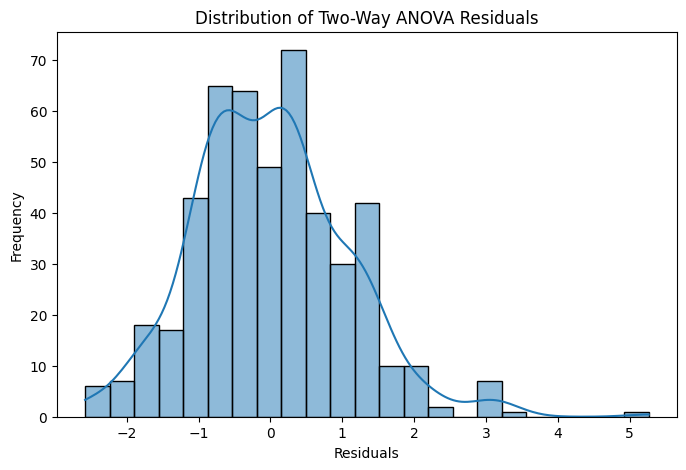

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Two-Way ANOVA Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.show()

In [107]:
# Spearman correlation: Night-time social media vs sleep duration

from scipy.stats import spearmanr

correlation, p_value = spearmanr(
    df[social_col],
    df[sleep_col]
)

print("Spearman Correlation Analysis")
print("Correlation coefficient:", correlation)
print("P-value:", p_value)
print("Sample size:", len(df))

Spearman Correlation Analysis
Correlation coefficient: -0.19474646380776536
P-value: 1.5980296366257642e-05
Sample size: 484


Task 3: Advanced Statistical Analysis & Hypothesis Testing

Research Title

Association Between Night-time Social Media Usage and Sleep Duration Among Undergraduate Medical Students.

1. Dataset Description

The dataset contained 484 responses and 33 variables. The primary variables selected were night-time social media usage (after 9 PM) and average sleep duration.

No missing values were observed in these two primary variables.

2. Descriptive Statistics

Variable| Mean| Standard Deviation| Median
Sleep duration| 6.73| 1.09| 7.00
Night-time social media usage| 1.58| 1.05| 1.125

3. Normality Testing

Shapiro-Wilk and Kolmogorov-Smirnov tests indicated that both primary variables deviated significantly from normality (p < 0.05).

Therefore, non-parametric tests were also considered in the analysis.

4. Independent Sample Tests

Welch's independent t-tests and Mann-Whitney U tests were conducted to compare sleep duration across gender codes and residence codes.

Neither comparison showed a statistically significant difference (p > 0.05).

5. One-Way ANOVA

One-Way ANOVA was conducted to compare sleep duration across four academic years.

F = 2.089, p = 0.101.

The result was not statistically significant. Tukey's post-hoc comparisons also showed no significant pairwise differences.

6. Two-Way ANOVA

Two-Way ANOVA examined the effects of academic year, gender code and their interaction on sleep duration.

- Academic year: F = 1.273, p = 0.283.
- Gender code: F = 0.483, p = 0.488.
- Academic year × Gender interaction: F = 2.726, p = 0.044.

The interaction was statistically significant.

Follow-up comparisons with Holm correction identified a significant difference between gender codes in Year 3 (adjusted p = 0.008). No significant differences were found in Years 1, 2 or 4.

7. Assumption Testing

The Shapiro-Wilk test indicated non-normality of Two-Way ANOVA residuals (p < 0.001).

Levene's test did not indicate unequal variances across the eight groups (p = 0.790).

The ANOVA findings were therefore interpreted with caution.

8. Primary Research Hypothesis – Spearman Correlation

Spearman's rank correlation test was conducted to examine the relationship between night-time social media usage and average sleep duration among 484 undergraduate medical students.

The analysis showed a weak negative correlation (ρ = −0.1947), which was statistically significant (p < 0.001).

This indicates that higher night-time social media usage is associated with shorter sleep duration.

Hypothesis Testing

- H0: There is no statistically significant association between night-time social media usage and sleep duration.
- H1: Higher night-time social media usage is associated with shorter sleep duration.

Since p < 0.05, the null hypothesis was rejected, and the alternative hypothesis was supported.

9. Overall Conclusion

The study found a statistically significant but weak negative association between night-time social media usage and sleep duration among undergraduate medical students.

The Two-Way ANOVA also identified a significant interaction between academic year and gender code. However, the main effects of academic year and gender code were not statistically significant.

Overall, the findings suggest that increased night-time social media usage tends to be associated with reduced sleep duration. However, the observational findings do not establish a causal relationship.
